## 1. Imports

In [16]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

try:
    from xgboost import XGBRegressor
    XGBOOST_AVAILABLE = True
except ImportError as e:
    XGBOOST_AVAILABLE = False
    print("XGBoost not available:", e)

## 2. Paths

In [17]:
PROJECT_DIR  = Path("/Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project")
DATA_VERSION = "v5_voltage_kfold5"

DATA_ROOT  = PROJECT_DIR / "processed_10hz" / "v2"
OUTPUT_DIR = PROJECT_DIR / "model_outputs" / "v2" / "04_baseline_models"
PLOT_DIR   = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = "target_energy_next_60s_wh"
ID_COLS    = ["log_id", "dataset_label"]

SPLITS = [
    ("fold_01", 42),
    ("fold_02", 42),
    ("fold_03", 42),
    ("fold_04", 42),
    ("fold_05", 42),
]

print(f"Data   : {DATA_ROOT}")
print(f"Output : {OUTPUT_DIR}")
print(f"Splits : {len(SPLITS)}")

Data   : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/processed_10hz/v2
Output : /Users/arjun/Documents/UAV thesis/uav-thesis/uav_px4_dataset_project/model_outputs/v2/04_baseline_models
Splits : 5


## 3. Load data

In [18]:
def load_split(split_name: str) -> tuple:
    """
    Load unscaled train/val/test parquets for one split.

    Parameters
    ----------
    split_name : str
        Folder name e.g. 'fold_01'.

    Returns
    -------
    train_df, val_df, test_df : pd.DataFrame
        Unscaled datasets for that split.
    """
    split_dir = DATA_ROOT / split_name
    base      = f"no_dr_interpolated_{DATA_VERSION}_{split_name}"

    train_df = pd.read_parquet(split_dir / f"train_{base}.parquet")
    val_df   = pd.read_parquet(split_dir / f"val_{base}.parquet")
    test_df  = pd.read_parquet(split_dir / f"test_{base}.parquet")

    return train_df, val_df, test_df


# quick check on split_01
train_df, val_df, test_df = load_split("fold_01")
print(f"Train : {train_df.shape}")
print(f"Val   : {val_df.shape}")
print(f"Test  : {test_df.shape}")
print(f"\nFeatures:")
feature_cols = [
    c for c in train_df.columns
    if c not in ID_COLS + [TARGET_COL]
    and pd.api.types.is_numeric_dtype(train_df[c])
]
for i, col in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {col}")

Train : (665216, 19)
Val   : (110878, 19)
Test  : (190831, 19)

Features:
   1. battery_status__cell_count
   2. battery_status__current_a
   3. battery_status__current_filtered_a
   4. battery_status__discharged_mah
   5. battery_status__remaining
   6. battery_status__scale
   7. battery_status__voltage_filtered_v
   8. battery_status__voltage_v
   9. cumulative_energy_wh
  10. power_w
  11. time_s
  12. is_idle
  13. power_w_rolling_std_3s
  14. voltage_per_cell
  15. voltage_filtered_per_cell
  16. voltage_per_cell_suspicious


## 4. Feature and target split

In [19]:
feature_cols = [
    c for c in train_df.columns
    if c not in ID_COLS + [TARGET_COL]
    and pd.api.types.is_numeric_dtype(train_df[c])
]

X_train = train_df[feature_cols].values
X_val   = val_df[feature_cols].values
X_test  = test_df[feature_cols].values

y_train = train_df[TARGET_COL].values
y_val   = val_df[TARGET_COL].values
y_test  = test_df[TARGET_COL].values

print(f"Features ({len(feature_cols)}):")
for i, col in enumerate(feature_cols, 1):
    print(f"  {i:2d}. {col}")
print(f"\nX_train : {X_train.shape}")
print(f"X_val   : {X_val.shape}")
print(f"X_test  : {X_test.shape}")

Features (16):
   1. battery_status__cell_count
   2. battery_status__current_a
   3. battery_status__current_filtered_a
   4. battery_status__discharged_mah
   5. battery_status__remaining
   6. battery_status__scale
   7. battery_status__voltage_filtered_v
   8. battery_status__voltage_v
   9. cumulative_energy_wh
  10. power_w
  11. time_s
  12. is_idle
  13. power_w_rolling_std_3s
  14. voltage_per_cell
  15. voltage_filtered_per_cell
  16. voltage_per_cell_suspicious

X_train : (665216, 16)
X_val   : (110878, 16)
X_test  : (190831, 16)


## 5. Helper functions

In [20]:
def rmse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """
    Compute Root Mean Squared Error.

    Parameters
    ----------
    y_true : np.ndarray
        Ground truth energy values in Wh.
    y_pred : np.ndarray
        Predicted energy values in Wh.

    Returns
    -------
    float
        RMSE value in Wh.
    """
    return np.sqrt(mean_squared_error(y_true, y_pred))


def evaluate_model(
    name: str,
    model,
    X_train: np.ndarray,
    y_train: np.ndarray,
    X_val: np.ndarray,
    y_val: np.ndarray,
    X_test: np.ndarray,
    y_test: np.ndarray,
    test_df: pd.DataFrame = None,
    fit_kwargs: dict = None 
) -> tuple:
    """
    Fit a model and evaluate it on validation and test sets.

    Computes MAE, RMSE and R² on both val and test splits.
    Optionally breaks down test metrics by dataset_label
    (normal vs abnormal) and computes per-flight MAE if
    log_id is present in test_df.

    Parameters
    ----------
    name : str
        Display name of the model used in output and result dict.
    model : sklearn-compatible estimator
        Any model with fit() and predict() methods.
    X_train : np.ndarray
        Training feature matrix, shape (n_train, n_features).
    y_train : np.ndarray
        Training target values, shape (n_train,).
    X_val : np.ndarray
        Validation feature matrix, shape (n_val, n_features).
    y_val : np.ndarray
        Validation target values, shape (n_val,).
    X_test : np.ndarray
        Test feature matrix, shape (n_test, n_features).
    y_test : np.ndarray
        Test target values, shape (n_test,).
    test_df : pd.DataFrame, optional
        Full test DataFrame containing log_id and dataset_label
        columns used for per-label and per-flight breakdowns.

    Returns
    -------
    result : dict
        Dictionary of evaluation metrics.
    model : fitted estimator
        The fitted model instance.
    test_pred : np.ndarray
        Predictions on the test set, shape (n_test,).
    """
    if fit_kwargs is None:
     fit_kwargs = {}
    print(f"\nTraining: {name}")
    model.fit(X_train, y_train, **fit_kwargs)

    val_pred  = model.predict(X_val)
    test_pred = model.predict(X_test)

    result = {
        "model"     : name,
        "val_MAE"   : mean_absolute_error(y_val,  val_pred),
        "val_RMSE"  : rmse(y_val,  val_pred),
        "val_R2"    : r2_score(y_val,  val_pred),
        "test_MAE"  : mean_absolute_error(y_test, test_pred),
        "test_RMSE" : rmse(y_test, test_pred),
        "test_R2"   : r2_score(y_test, test_pred),
        "test_P95"  : float(np.percentile(np.abs(y_test - test_pred), 95)),
    }

    if test_df is not None:
        for label in ["normal", "abnormal"]:
            mask = test_df["dataset_label"].values == label
            if mask.sum() == 0:
                continue
            yt = y_test[mask]
            yp = test_pred[mask]
            result[f"test_MAE_{label}"]  = mean_absolute_error(yt, yp)
            result[f"test_RMSE_{label}"] = rmse(yt, yp)
            result[f"test_R2_{label}"]   = r2_score(yt, yp)
            print(f"  [{label:8s}]  MAE={result[f'test_MAE_{label}']:.4f}  "
                  f"RMSE={result[f'test_RMSE_{label}']:.4f}  "
                  f"R²={result[f'test_R2_{label}']:.4f}")

    if test_df is not None and "log_id" in test_df.columns:
        tmp = test_df[["log_id"]].copy().reset_index(drop=True)
        tmp["y_true"] = y_test
        tmp["y_pred"] = test_pred
        flight_mae = (
            tmp.groupby("log_id")
            .apply(lambda g: mean_absolute_error(g["y_true"], g["y_pred"]),
                   include_groups=False)
            .rename("flight_MAE")
        )
        result["test_flight_MAE_mean"]   = flight_mae.mean()
        result["test_flight_MAE_median"] = flight_mae.median()
        print(f"  [flight]   mean MAE={result['test_flight_MAE_mean']:.4f}  "
              f"median MAE={result['test_flight_MAE_median']:.4f}")

    print(f"  [overall]  test MAE={result['test_MAE']:.4f}  "
          f"RMSE={result['test_RMSE']:.4f}  R²={result['test_R2']:.4f}")

    return result, model, test_pred


def save_plots(name: str, y_test: np.ndarray, test_pred: np.ndarray) -> None:
    """
    Save three diagnostic plots for a fitted model.

    Saves predicted-vs-actual scatter, residual distribution
    histogram, and residuals-vs-predicted scatter to PLOT_DIR.

    Parameters
    ----------
    name : str
        Model name used to construct output filenames.
    y_test : np.ndarray
        Ground truth test values, shape (n_test,).
    test_pred : np.ndarray
        Model predictions on test set, shape (n_test,).

    Returns
    -------
    None
    """
    safe      = name.lower().replace(" ", "_")
    residuals = y_test - test_pred

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(y_test, test_pred, alpha=0.15, s=4, color="steelblue")
    lim = max(y_test.max(), test_pred.max()) * 1.05
    ax.plot([0, lim], [0, lim], "r--", linewidth=1)
    ax.set_xlabel("Actual (Wh)")
    ax.set_ylabel("Predicted (Wh)")
    ax.set_title(f"Predicted vs Actual — {name}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"pred_vs_actual__{safe}.png", dpi=150)
    plt.close()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(residuals, bins=100, color="steelblue", alpha=0.8, edgecolor="none")
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xlabel("Residual (Wh)")
    ax.set_ylabel("Count")
    ax.set_title(f"Residual Distribution — {name}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"residuals__{safe}.png", dpi=150)
    plt.close()

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(test_pred, residuals, alpha=0.10, s=4, color="slategray")
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xlabel("Predicted (Wh)")
    ax.set_ylabel("Residual (Wh)")
    ax.set_title(f"Residuals vs Predicted — {name}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"resid_vs_pred__{safe}.png", dpi=150)
    plt.close()

    print(f"  Plots saved: {safe}")


def save_feature_importance(
    name: str,
    model,
    feature_cols: list
) -> None:
    """
    Save feature importance plot and CSV for tree-based models.

    Only runs if the model has a feature_importances_ attribute
    (Random Forest, XGBoost). Silently skips otherwise.

    Parameters
    ----------
    name : str
        Model name used to construct output filenames.
    model : fitted estimator
        Trained model instance. Must have feature_importances_.
    feature_cols : list of str
        Feature column names in the same order as the training matrix.

    Returns
    -------
    None
    """
    if not hasattr(model, "feature_importances_"):
        return

    safe = name.lower().replace(" ", "_")
    imp  = pd.Series(
        model.feature_importances_, index=feature_cols
    ).sort_values(ascending=False)

    fig, ax = plt.subplots(figsize=(10, 6))
    imp.plot(kind="bar", ax=ax, color="steelblue", alpha=0.8)
    ax.set_title(f"Feature Importance — {name}")
    ax.set_ylabel("Importance")
    ax.set_xlabel("Feature")
    ax.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / f"feat_imp__{safe}.png", dpi=150)
    plt.close()

    imp.to_csv(PLOT_DIR / f"feat_imp__{safe}.csv", header=["importance"])
    print(f"  Feature importance saved: {safe}")


print("Helper functions defined")

Helper functions defined


## 6. Naive baselines

In [21]:
# ============================================================
# NAIVE MODELS ACROSS 5 folds
# ============================================================

all_naive_results = []

for split_name, seed in SPLITS:
    print(f"\n{'=' * 60}")
    print(f"SPLIT: {split_name}")
    print(f"{'=' * 60}")

    train_df, val_df, test_df = load_split(split_name)

    y_train = train_df[TARGET_COL].values
    y_val   = val_df[TARGET_COL].values
    y_test  = test_df[TARGET_COL].values

    naive_results = []


    # Baseline 1: Always predict the training mean
    mean_value = y_train.mean()

    mean_val_pred = np.full(len(y_val), mean_value)
    mean_test_pred = np.full(len(y_test), mean_value)

    naive_results.append({
        "split": split_name,
        "seed": seed,
        "model": "Mean baseline",
        "val_MAE": mean_absolute_error(y_val, mean_val_pred),
        "val_RMSE": rmse(y_val, mean_val_pred),
        "val_R2": r2_score(y_val, mean_val_pred),
        "test_MAE": mean_absolute_error(y_test, mean_test_pred),
        "test_RMSE": rmse(y_test, mean_test_pred),
        "test_R2": r2_score(y_test, mean_test_pred),
    })

    print(
        f"Mean baseline: "
        f"test MAE = {naive_results[-1]['test_MAE']:.4f}"
    )

    # Baseline 2: Current power continued for 60 seconds
    power_val_pred = (
        val_df["power_w"].values * (60 / 3600)
    )

    power_test_pred = (
        test_df["power_w"].values * (60 / 3600)
    )

    naive_results.append({
        "split": split_name,
        "seed": seed,
        "model": "Power heuristic",
        "val_MAE": mean_absolute_error(y_val, power_val_pred),
        "val_RMSE": rmse(y_val, power_val_pred),
        "val_R2": r2_score(y_val, power_val_pred),
        "test_MAE": mean_absolute_error(y_test, power_test_pred),
        "test_RMSE": rmse(y_test, power_test_pred),
        "test_R2": r2_score(y_test, power_test_pred),
    })

    print(
        f"Power heuristic: "
        f"test MAE = {naive_results[-1]['test_MAE']:.4f}"
    )

    all_naive_results.extend(naive_results)


# One row for each baseline on each split
naive_all_splits_df = pd.DataFrame(all_naive_results).round(4)

display(naive_all_splits_df)

naive_all_splits_df.to_csv(
    OUTPUT_DIR / "naive_baseline_all_splits_results.csv",
    index=False
)

print(
    f"\nDone. {len(naive_all_splits_df)} result rows saved."
)
naive_summary_df = (
    naive_all_splits_df
    .groupby("model")[
        [
            "val_MAE",
            "val_RMSE",
            "val_R2",
            "test_MAE",
            "test_RMSE",
            "test_R2",
        ]
    ]
    .agg(["mean", "std"])
    .round(4)
)

display(naive_summary_df)

naive_summary_df.to_csv(
    OUTPUT_DIR / "naive_baseline_10_split_summary.csv"
)


SPLIT: fold_01
Mean baseline: test MAE = 1.7307
Power heuristic: test MAE = 0.3523

SPLIT: fold_02
Mean baseline: test MAE = 3.0580
Power heuristic: test MAE = 0.5231

SPLIT: fold_03
Mean baseline: test MAE = 2.0387
Power heuristic: test MAE = 0.3351

SPLIT: fold_04
Mean baseline: test MAE = 1.6174
Power heuristic: test MAE = 0.3069

SPLIT: fold_05
Mean baseline: test MAE = 1.9231
Power heuristic: test MAE = 0.5522


,split,seed,model,val_MAE,val_RMSE,val_R2,test_MAE,test_RMSE,test_R2
0,fold_01,42,Mean baseline,1.2774,1.5291,-0.0692,1.7307,2.1506,-0.0936
1,fold_01,42,Power heuristic,0.4220,0.8330,0.6827,0.3523,0.7669,0.8609
2,fold_02,42,Mean baseline,2.0867,2.4949,-0.0251,3.0580,5.7714,-0.0276
3,fold_02,42,Power heuristic,0.4916,1.0303,0.8252,0.5231,1.5933,0.9217
4,fold_03,42,Mean baseline,1.4798,1.6165,-0.2575,2.0387,3.6712,-0.0208
5,fold_03,42,Power heuristic,0.3173,0.5717,0.8427,0.3351,0.7604,0.9562
6,fold_04,42,Mean baseline,1.2395,1.5247,-0.0004,1.6174,1.8307,-1.3930
7,fold_04,42,Power heuristic,0.4191,0.7775,0.7399,0.3069,0.5307,0.7989
8,fold_05,42,Mean baseline,3.7047,7.2402,-0.0951,1.9231,2.3040,-0.0946
9,fold_05,42,Power heuristic,0.7028,1.9632,0.9195,0.5522,1.1895,0.7083



Done. 10 result rows saved.


val_MAE         val_RMSE          val_R2         test_MAE  \
                   mean     std     mean     std    mean     std     mean   
model                                                                       
Mean baseline    1.9576  1.0339   2.8811  2.4707 -0.0895  0.1009   2.0736   
Power heuristic  0.4706  0.1439   1.0351  0.5439  0.8020  0.0923   0.4139   

                        test_RMSE         test_R2          
                    std      mean     std    mean     std  
model                                                      
Mean baseline    0.5742    3.1456  1.6278 -0.3259  0.5975  
Power heuristic  0.1146    0.9682  0.4227  0.8492  0.0990

## 7. Train all models : BASELINE MODELS — 10 SPLITS

In [22]:


all_split_results = []

for split_name, seed in SPLITS:
    print(f"\n{'='*60}")
    print(f"SPLIT: {split_name}")
    print(f"{'='*60}")

    train_df, val_df, test_df = load_split(split_name)

    feature_cols = [
        c for c in train_df.columns
        if c not in ID_COLS + [TARGET_COL]
        and pd.api.types.is_numeric_dtype(train_df[c])
    ]

    X_train = train_df[feature_cols].values
    X_val   = val_df[feature_cols].values
    X_test  = test_df[feature_cols].values

    y_train = train_df[TARGET_COL].values
    y_val   = val_df[TARGET_COL].values
    y_test  = test_df[TARGET_COL].values

    models = {
        "Linear Regression": LinearRegression(),
        "Random Forest": RandomForestRegressor(
            n_estimators=300,
            max_depth=15,
            min_samples_leaf=10,
            max_features=0.5,
            random_state=seed,
            n_jobs=-1
        ),
    }

    if XGBOOST_AVAILABLE:
        models["XGBoost"] = XGBRegressor(
            n_estimators=1000,
            max_depth=5,
            learning_rate=0.01,
            subsample=0.8,
            colsample_bytree=0.8,
            min_child_weight=10,
            random_state=seed,
            n_jobs=-1,
            verbosity=0,
            tree_method="hist",
            early_stopping_rounds=50,
        )

    for model_name, model in models.items():
        fit_kwargs = {}
        if model_name == "XGBoost":
            fit_kwargs["eval_set"] = [(X_val, y_val)]
            fit_kwargs["verbose"]  = False

        result, fitted_model, test_pred = evaluate_model(
            name=model_name,
            model=model,
            X_train=X_train, y_train=y_train,
            X_val=X_val,     y_val=y_val,
            X_test=X_test,   y_test=y_test,
            test_df=test_df.reset_index(drop=True),
            fit_kwargs=fit_kwargs
        )

        result["split"]      = split_name
        result["seed"]       = seed
        all_split_results.append(result)

 # save plots for every fold — named by fold so they don't overwrite
        save_plots(f"{model_name}_{split_name}", y_test, test_pred)
        save_feature_importance(f"{model_name}_{split_name}", fitted_model, feature_cols)

        # save model artefact for every fold
        safe_name = model_name.lower().replace(" ", "_")
        joblib.dump(fitted_model, OUTPUT_DIR / f"{safe_name}_{split_name}.joblib")

raw_results_df = pd.DataFrame(all_split_results)
raw_results_df.to_csv(OUTPUT_DIR / "all_splits_raw_results.csv", index=False)
print(f"\nDone. {len(raw_results_df)} result rows saved.")


SPLIT: fold_01

Training: Linear Regression
  [normal  ]  MAE=0.2502  RMSE=0.4729  R²=0.9407
  [abnormal]  MAE=0.7727  RMSE=1.1499  R²=0.7441
  [flight]   mean MAE=0.3326  median MAE=0.3022
  [overall]  test MAE=0.4044  RMSE=0.7401  R²=0.8705
  Plots saved: linear_regression_fold_01

Training: Random Forest
  [normal  ]  MAE=0.3385  RMSE=0.7793  R²=0.8389
  [abnormal]  MAE=0.5511  RMSE=0.9481  R²=0.8260
  [flight]   mean MAE=0.3838  median MAE=0.1564
  [overall]  test MAE=0.4013  RMSE=0.8326  R²=0.8361
  Plots saved: random_forest_fold_01
  Feature importance saved: random_forest_fold_01

Training: XGBoost
  [normal  ]  MAE=0.2746  RMSE=0.5826  R²=0.9099
  [abnormal]  MAE=0.6314  RMSE=1.1431  R²=0.7471
  [flight]   mean MAE=0.3345  median MAE=0.1910
  [overall]  test MAE=0.3798  RMSE=0.7905  R²=0.8523
  Plots saved: xgboost_fold_01
  Feature importance saved: xgboost_fold_01

SPLIT: fold_02

Training: Linear Regression
  [normal  ]  MAE=0.3151  RMSE=0.7345  R²=0.8642
  [abnormal]  MAE

## 8. Results table

In [23]:
raw_results_df = pd.read_csv(OUTPUT_DIR / "all_splits_raw_results.csv")

summary = (
    raw_results_df
    .groupby("model")[["test_MAE", "test_RMSE", "test_R2",
                        "test_MAE_normal", "test_MAE_abnormal"]]
    .agg(["mean", "std"])
    .round(4)
)

print("=" * 70)
print("5-FOLD MEAN ± STD — ALL BASELINE MODELS")
print("=" * 70)
display(summary)

# flat summary for easy reading
flat = []
for model in raw_results_df["model"].unique():
    sub = raw_results_df[raw_results_df["model"] == model]
    flat.append({
        "model"              : model,
        "test_MAE_mean"      : sub["test_MAE"].mean().round(4),
        "test_MAE_std"       : round(sub["test_MAE"].std(), 4),
        "test_RMSE_mean"     : sub["test_RMSE"].mean().round(4),
        "test_R2_mean"       : sub["test_R2"].mean().round(4),
        "MAE_normal_mean"    : sub["test_MAE_normal"].mean().round(4),
        "MAE_abnormal_mean"  : sub["test_MAE_abnormal"].mean().round(4),
    })

flat_df = pd.DataFrame(flat).sort_values("test_MAE_mean").reset_index(drop=True)
flat_df.index += 1

print("\n--- FLAT SUMMARY (sorted by mean test MAE) ---")
display(flat_df)
flat_df.to_csv(OUTPUT_DIR / "baseline_10split_summary.csv", index=False)

print(f"\nBest model : {flat_df.iloc[0]['model']}")
print(f"Mean MAE   : {flat_df.iloc[0]['test_MAE_mean']:.4f} ± {flat_df.iloc[0]['test_MAE_std']:.4f} Wh")

5-FOLD MEAN ± STD — ALL BASELINE MODELS


test_MAE         test_RMSE         test_R2          \
                      mean     std      mean     std    mean     std   
model                                                                  
Linear Regression    0.467  0.1406    0.9974  0.5048  0.8520  0.1029   
Random Forest        0.747  0.2933    1.7443  0.9744  0.2920  1.0738   
XGBoost              0.624  0.2746    1.4119  1.0333  0.7899  0.0576   

                  test_MAE_normal         test_MAE_abnormal          
                             mean     std              mean     std  
model                                                                
Linear Regression          0.2927  0.0441            0.8722  0.4036  
Random Forest              0.4277  0.2141            1.5055  0.9055  
XGBoost                    0.3317  0.0992            1.2999  0.9606


--- FLAT SUMMARY (sorted by mean test MAE) ---


,model,test_MAE_mean,test_MAE_std,test_RMSE_mean,test_R2_mean,MAE_normal_mean,MAE_abnormal_mean
1,Linear Regression,0.467,0.1406,0.9974,0.8520,0.2927,0.8722
2,XGBoost,0.624,0.2746,1.4119,0.7899,0.3317,1.2999
3,Random Forest,0.747,0.2933,1.7443,0.2920,0.4277,1.5055



Best model : Linear Regression
Mean MAE   : 0.4670 ± 0.1406 Wh


## 9. Normal vs abnormal comparison table

In [24]:
# Load the 10-split results
raw_results_df = pd.read_csv(
    OUTPUT_DIR / "all_splits_raw_results.csv"
)

# Sort by overall test MAE
results_df_sorted = (
    raw_results_df
    .sort_values(["model", "test_MAE"])
    .reset_index(drop=True)
)

label_cols = [
    "split",
    "model",
    "test_MAE",
    "test_MAE_normal",
    "test_MAE_abnormal",
    "test_R2",
    "test_R2_normal",
    "test_R2_abnormal",
]

label_cols_present = [
    c for c in label_cols
    if c in results_df_sorted.columns
]

print("=" * 70)
print("NORMAL vs ABNORMAL BREAKDOWN")
print("=" * 70)

display(
    results_df_sorted[label_cols_present].round(4)
)

results_df_sorted[label_cols_present].to_csv(
    OUTPUT_DIR / "baseline_results_by_label.csv",
    index=False
)

NORMAL vs ABNORMAL BREAKDOWN


,split,model,test_MAE,test_MAE_normal,test_MAE_abnormal,test_R2,test_R2_normal,test_R2_abnormal
0,fold_04,Linear Regression,0.3000,0.3014,0.2954,0.8511,0.8493,0.8588
1,fold_01,Linear Regression,0.4044,0.2502,0.7727,0.8705,0.9407,0.7441
2,fold_03,Linear Regression,0.4203,0.2467,0.8622,0.9515,0.9061,0.9444
3,fold_05,Linear Regression,0.5462,0.3501,1.0236,0.6812,0.8988,0.1081
4,fold_02,Linear Regression,0.6641,0.3151,1.4070,0.9059,0.8642,0.8935
5,fold_01,Random Forest,0.4013,0.3385,0.5511,0.8361,0.8389,0.8260
6,fold_05,Random Forest,0.5864,0.4463,0.9274,0.8067,0.8190,0.6419
7,fold_03,Random Forest,0.6880,0.2075,1.9105,0.7732,0.9275,0.6857
8,fold_04,Random Forest,0.8967,0.7783,1.2835,-1.6255,-1.3459,-2.7992
9,fold_02,Random Forest,1.1627,0.3677,2.8550,0.6697,0.8101,0.5956


In [25]:
summary_by_label = (
    raw_results_df
    .groupby("model")[
        [
            "test_MAE",
            "test_MAE_normal",
            "test_MAE_abnormal",
            "test_R2",
            "test_R2_normal",
            "test_R2_abnormal",
        ]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("=" * 70)
print("5-FOLD NORMAL vs ABNORMAL MEAN ± STD")
print("=" * 70)

display(summary_by_label)

summary_by_label.to_csv(
    OUTPUT_DIR / "baseline_results_by_label_10split_summary.csv"
)

5-FOLD NORMAL vs ABNORMAL MEAN ± STD


test_MAE         test_MAE_normal         test_MAE_abnormal  \
                      mean     std            mean     std              mean   
model                                                                          
Linear Regression    0.467  0.1406          0.2927  0.0441            0.8722   
Random Forest        0.747  0.2933          0.4277  0.2141            1.5055   
XGBoost              0.624  0.2746          0.3317  0.0992            1.2999   

                          test_R2         test_R2_normal          \
                      std    mean     std           mean     std   
model                                                              
Linear Regression  0.4036  0.8520  0.1029         0.8918  0.0361   
Random Forest      0.9055  0.2920  1.0738         0.4099  0.9826   
XGBoost            0.9606  0.7899  0.0576         0.8603  0.0624   

                  test_R2_abnormal          
                              mean     std  
model                                       
Linear Regression           0.7098  0.3443  
Random Forest              -0.0100  1.5616  
XGBoost                     0.7018  0.0572

## 10. Comparison bar chart

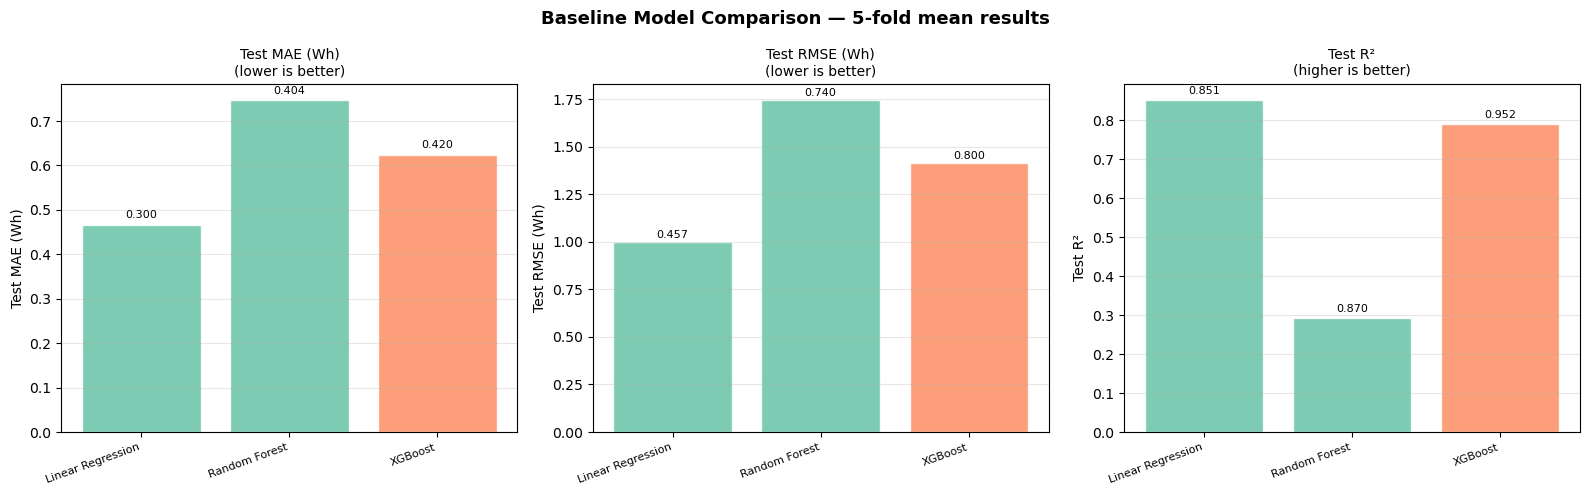

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f"Baseline Model Comparison — 5-fold mean results",
    fontsize=13, fontweight="bold"
)

metrics = [
    ("test_MAE",      "Test MAE (Wh)",  "lower is better"),
    ("test_RMSE",     "Test RMSE (Wh)", "lower is better"),
    ("test_R2",       "Test R²",        "higher is better"),
]
summary = (
    results_df_sorted
    .groupby("model", sort=False)[["test_MAE", "test_RMSE", "test_R2"]]
    .mean()
    .reset_index()
)
colors = plt.cm.Set2(np.linspace(0, 1, len(results_df_sorted)))

for ax, (metric, ylabel, note) in zip(axes, metrics):
    bars = ax.bar(
        summary["model"],
        summary[metric],
        color=colors, alpha=0.85, edgecolor="white"
    )
    for bar, val in zip(bars, results_df_sorted[metric]):
        ax.text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.01,
            f"{val:.3f}",
            ha="center", va="bottom", fontsize=8
        )
    ax.set_title(f"{ylabel}\n({note})", fontsize=10)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(summary)))
    ax.set_xticklabels(summary["model"], rotation=20, ha="right", fontsize=8)
    ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(PLOT_DIR / "baseline_comparison_bar.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

## 11. Normal vs abnormal MAE comparison

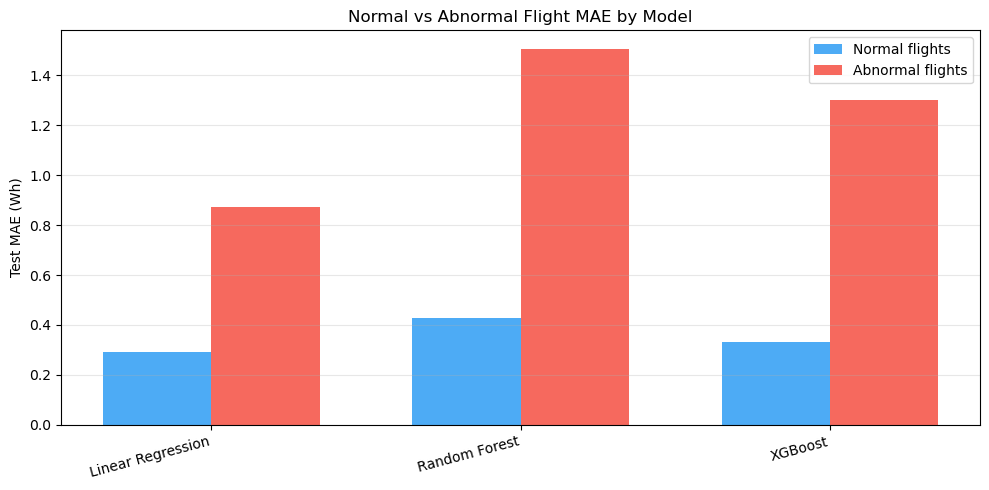

In [27]:
if "test_MAE_normal" in results_df_sorted.columns:
    summary = (
        results_df_sorted
        .groupby("model", sort=False)[["test_MAE_normal", "test_MAE_abnormal"]]
        .mean()
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(10, 5))
    x     = np.arange(len(summary))
    width = 0.35

    ax.bar(x - width/2, summary["test_MAE_normal"],
           width, label="Normal flights",   color="#2196F3", alpha=0.8)
    ax.bar(x + width/2, summary["test_MAE_abnormal"],
           width, label="Abnormal flights", color="#F44336", alpha=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels(summary["model"], rotation=15, ha="right")
    ax.set_ylabel("Test MAE (Wh)")
    ax.set_title("Normal vs Abnormal Flight MAE by Model")
    ax.legend()
    ax.grid(True, alpha=0.3, axis="y")
    plt.tight_layout()
    plt.savefig(PLOT_DIR / "baseline_normal_vs_abnormal_mae.png", dpi=150)
    plt.show()
    plt.close()